In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

sns.set_theme(style="whitegrid")
OUT = Path("figures"); OUT.mkdir(exist_ok=True)

COLOURS = {"Developed": "#1f77b4", "Developing": "#d95f02"}
ISO3 = {"Switzerland": "CHE", "United States": "USA", "Germany": "DEU",
        "South Africa": "ZAF", "China": "CHN", "India": "IND"}

comp = pd.read_csv("clean-pt2/companies_summary_6countries.csv")
comp["iso3"] = comp["country"].map(ISO3)

totals = comp[comp["field"] == "All"].copy()      # country totals
fields = comp[comp["field"] != "All"].copy()      # field level rows

print(comp["country"].unique())                   # check names match ISO3 keys
print(fields["field"].nunique(), "fields")

<StringArray>
['China', 'Germany', 'India', 'South Africa', 'Switzerland', 'United States']
Length: 6, dtype: str
36 fields


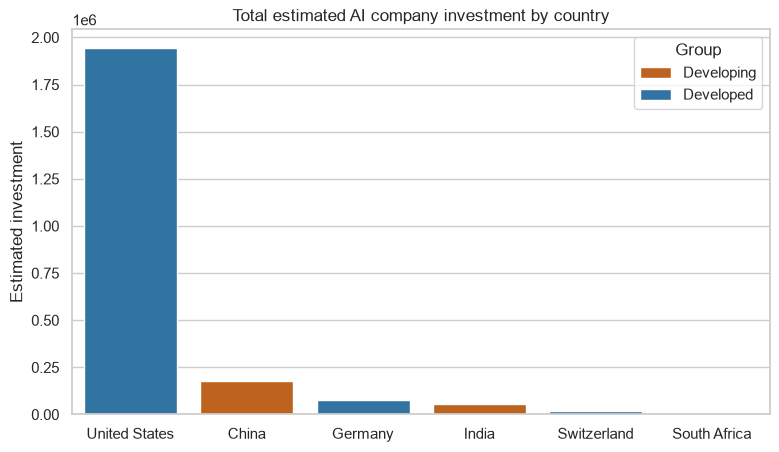

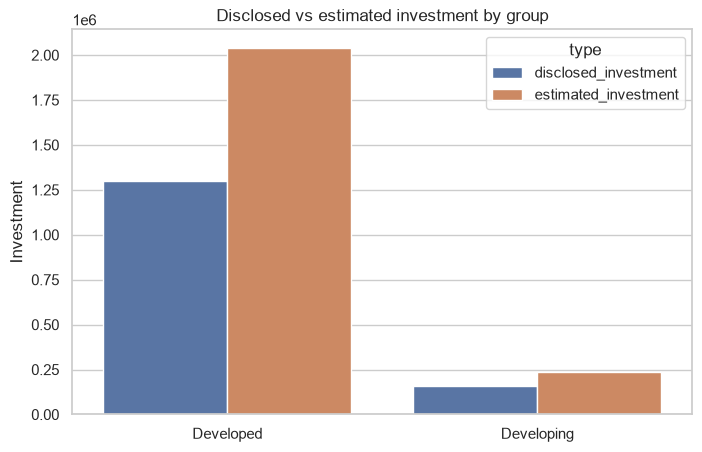

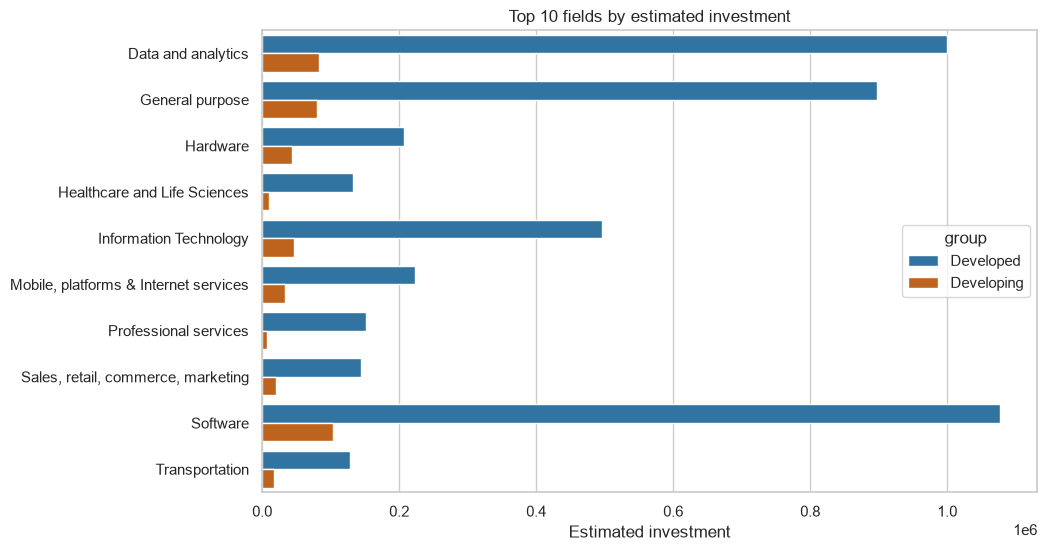

In [2]:
# Total estimated investment by country
order = totals.sort_values("estimated_investment", ascending=False)["country"]
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=totals, x="country", y="estimated_investment", hue="group",
            palette=COLOURS, order=order, dodge=False, ax=ax)
ax.set_title("Total estimated AI company investment by country")
ax.set_xlabel(""); ax.set_ylabel("Estimated investment")
ax.legend(title="Group")
fig.savefig(OUT / "companies_total_by_country.png", dpi=300, bbox_inches="tight")
plt.show()

# Developed vs developing totals, disclosed and estimated side by side
grp = (totals.groupby("group")[["disclosed_investment", "estimated_investment"]]
       .sum().reset_index().melt(id_vars="group", var_name="type", value_name="investment"))
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=grp, x="group", y="investment", hue="type", ax=ax)
ax.set_title("Disclosed vs estimated investment by group")
ax.set_xlabel(""); ax.set_ylabel("Investment")
fig.savefig(OUT / "companies_group_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Top 10 fields by estimated investment, split by group
top = fields.groupby(["group", "field"])["estimated_investment"].sum().reset_index()
top_fields = top.groupby("field")["estimated_investment"].sum().nlargest(10).index
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top[top["field"].isin(top_fields)], y="field", x="estimated_investment",
            hue="group", palette=COLOURS, ax=ax)
ax.set_title("Top 10 fields by estimated investment")
ax.set_xlabel("Estimated investment"); ax.set_ylabel("")
fig.savefig(OUT / "companies_top_fields.png", dpi=300, bbox_inches="tight")
plt.show()

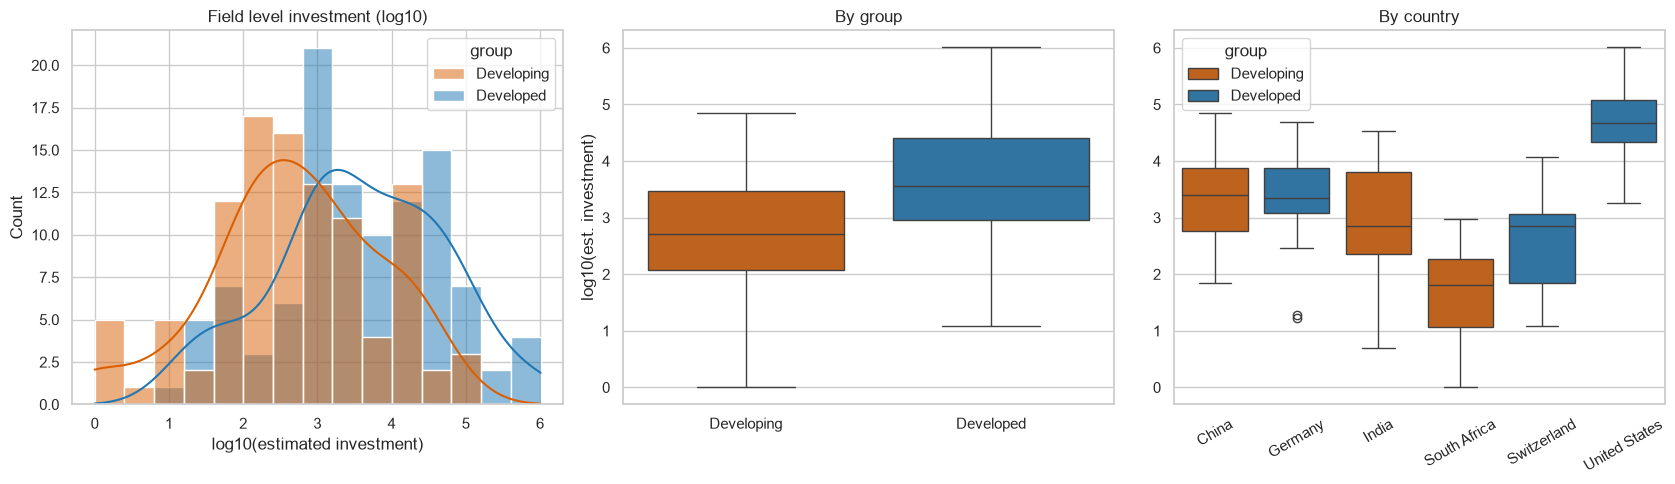

In [3]:
# Log transform so a few large fields don't dominate the shape
fields["log_est"] = np.log10(fields["estimated_investment"].clip(lower=1))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.histplot(data=fields, x="log_est", hue="group", palette=COLOURS,
             kde=True, bins=15, alpha=0.5, ax=axes[0])
axes[0].set_title("Field level investment (log10)")
axes[0].set_xlabel("log10(estimated investment)")

sns.boxplot(data=fields, x="group", y="log_est", hue="group",
            palette=COLOURS, legend=False, ax=axes[1])
axes[1].set_title("By group")
axes[1].set_xlabel("")
axes[1].set_ylabel("log10(est. investment)")

sns.boxplot(data=fields, x="country", y="log_est", hue="group",
            palette=COLOURS, dodge=False, ax=axes[2])
axes[2].set_title("By country")
axes[2].set_xlabel("")
axes[2].set_ylabel("")
axes[2].tick_params(axis="x", rotation=30)

fig.tight_layout()
fig.savefig(OUT / "companies_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
fig = px.choropleth(totals, locations="iso3", color="estimated_investment",
                    hover_name="country", color_continuous_scale="Viridis",
                    labels={"estimated_investment": "Estimated investment"},
                    title="Total estimated AI company investment")
fig.update_geos(showcountries=True, projection_type="natural earth")
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0))
fig.write_html(OUT / "companies_map.html")
fig.show()